# Trace the Sample through Its Parents

Use the same founder-and-expansion population and the same sampled DNA.
Fix site 5,000 on chromosome 1 and trace the first twelve sampled haplotypes.
Each site has its own genealogy even though the chromosome recombines.
The recorded tree describes this realized sample; the coalescent models
how such genealogies vary across populations.



In [1]:
library(hpgR)
options(repr.plot.width = 9, repr.plot.height = 4.2, repr.plot.pointsize = 13,
        repr.plot.bg = "white", warn = 1)
blue <- "#265991"; orange <- "#D65F22"
drawFigure <- function(name, draw, width = 9, height = 3) {
    directory <- Sys.getenv("P8149_FIGURE_DIR")
    if (nzchar(directory)) {
        dir.create(directory, recursive = TRUE, showWarnings = FALSE)
        pdf(file.path(directory, paste0(name, ".pdf")), width = width, height = height,
            family = "Helvetica", pointsize = 13, useDingbats = FALSE, bg = "white")
        tryCatch(draw(), finally = dev.off())
    }
    if ("IRkernel" %in% loadedNamespaces()) draw()
    invisible(NULL)
}


In [2]:
observed <- (function() {
  encoded <- c(
    "..."
  )
  payload <- memDecompress(base64enc::base64decode(paste0(encoded, collapse = "")), "gzip")
  con <- rawConnection(payload)
  on.exit(close(con))
  readRDS(con)
})()


ancestry_truth <- (function() {
  encoded <- c(
    "H4sIAAAAAAAAA+1dXWwj13U+IoeUqJ/d0UorB0VSEAsjNoKNsdL6ZzeOs7TWP2vXa3iRBnAbOFpKHEnsSiSXpGI3TRACRYC8pCjQ",
    "h/4X2zovQdEiQRDAeUggdP3SB6MG+tAnA5sWCGI7aV3krQXqzuU938yZwyEl7lJcUZoFuN/cO3Pvmcv55p6P554ZvTpJRGlyMmlK",
    "Z/xNynzpt5/77AWi1JxfcPzPjP/xt+e+7eM3iD79J0QPfYfo6ptEL/81UfOHRDv/QPSXt4n+6idE//SvRLffIXr/P4g+eI/G3F/T",
    "2OyvaOxCmij3NtGnXuK+5xhzvv259kmk2rYe8D9j/ifVrrPnYM4s63/G/c+EbUPmxKf8zzSf4wn/c9L/uP5n1v+csjZo3v+c9j8L",
    "7b5T7eOMjQP9V/gM4+OMTzIWgC2LTzNe5vrnGK8xNr9v8evvomuXzPk77e8gdWUx2FoKts4HW48GW48FW48HW08EWxeCrYu8lb6y",
    "eC7cXAw3l3zIfez/Gzw65pKPsalMpbjtNXi8aZxfucRbTrO87fF2rlHcrm15K/7OaB+5evX1R9CP4UjKfNu+rfe1sbWtYgPGUDlZ",
    "KjaLj6zX/fZ+6f8UTRe4S1AP9AMFzWeWQiqCjqAkaAlqWnpaiqJ/TXN5C2TI3h7GrkP2lpllu7A1w+dzmu2ZPlPcZiGgqKaqpmwH",
    "dYEti5/mMqgMnOf6TzCeUeXf4uOeYazVLN78yOJ1ayikvrlkYx9TlBLZWrHuVZrBhdwsb4Ej2S2vstHctA1TH1OUAx/Y+jQ67HrZ",
    "6T/5a8MRJ9aq27XiWnOlXGk2vJtqr7NabHhcN0P2wsxwT+aLTxcetsO59FEU+RhzLtP39/7GaU+L7Qd4un5A1I2JbTnctNh2xHZG",
    "bGfF9rjYnhDbObE9KbanYs4xReH9gvKU2p8VtlJ8PrCX5o9uI8eAew7t5LHjYuxOl2MccQ7yXKdi2u7l7qapbzcZ3D+a0CdL3rpX",
    "r3ullUazXq5s2N2Zj9VldckyNDUUTx3aJbaLuwOn/XjdW6vWS14pX6v6t2K+Wfe8/Hq9up1vbnr5xqY/MZTy69X668W6OaS2s1Vs",
    "lqsVnsglMQWR2zrHnOHYpR//2X//y9/+8CvRfZFJyMGcsbbpm602qoFPmqhVG+W2NVt2N7yK1yyvrah6xy95aoYSlvaenSLnkwuc",
    "Z7XkOz0ueKWNoDDNvlIeMBn4T9SMBadXr1Yxt075Lda8Sqnoz3roetvvZgvT7XaxfsOr29M6wtJuiRF+8QuMlxgLjE8zLjPCz0Hi",
    "bV63WH8XXbt0lKVdh+ven5rrcNzv7/fWGLpem6TQP02zDbNvgizfjY0M2zScN2c9zjbn2Kaxk2I7Dvdr9Rp4p/kHnGBkeRHwkREy",
    "I+Cny6h5CoReg457UNkBf1fvWGQeF363ZQ+433rNYf/V4ccSNTYUNSaP02rMEfu14kpTpyqTSi0jzjmuPdSVVmzSw8xQeLdi/15e",
    "CCot1UebAai0bDcau3QM5JgJObEcK13bcX721FvRfcORY7CUyLHDJ8fgnhC2uMj4OUYtyyDDnuXyi4y1PGMNXbuUyLFRlmPtu4As",
    "pw1/4dhOUijHjN0JCp2j4bq5H6bZ5iyF4bM5knIMvNP80zx81GIgvz6n2kFmFRSCp5qvQO638BhjedfiDS7f2I3YSeTYMZdjWdEG",
    "wS8cm6ZoYAoSLa4+S53yJyf6gvSbEGXcWSjjDsOPo14yDP1CrvWSX4n0GqD0Mit9LL3++fm//98/emQjum840guWEul1+KSXywhX",
    "lmdEBGKREYubcGUvcBnS67Vdi7VddG16TqTX6Eov/DaHozI2DIcNxw3XIceMLfmbH1GwkxSVXjhnK71c5g1QSzFEqPKMDytcVAhJ",
    "pnkKPKPaI4KLlc5Xdi1eK1hcvWWxZvcn0iuRXhH5I/tIi7JsA48go1pSrsUdIyNnGVEn1yNlBE1KN9jWMgttE5k1SJklR9kjwmUS",
    "rYYjs2ApkVmHV2YhUSeIaLUsYsHmssJgwZHxVa5n90SJzDoqMgtLE4bPhsPm7Ay/Mc1AdqUplFYu2zjFNmR0K15m6YQxtcAY8FHz",
    "ssCo+Qn8JKP+GeGq/S9wv1e5/CKXi8T/EpmVyCxRlsemKLw7pKSSMiyuDymxsBgp+8mIdjqta1z1EXcM4s17eadEbg1IbvWKapmc",
    "9uHILVhK5Nbhk1uICiwx6oUWvcDzeUbIrJe4vHXL4s0aunYpkVujLLcMbw2P8Vs6y3ZSbEc6P8NtR9iZZRsu2zD8z5FcUNRRqSWF",
    "4CGTCXwMFhb1AmSeUfMU0THYeYJR5/F7tywqHiN6m8itYy63xikqlXQ2PWZ+1DniOFkPqZYWbdG3zBdzYuqzom3c/m7RLOmR5PE6",
    "x6vb8UkE7F4lmWRtjwiYecRwOJIMlhJJdvgkGVwfXBlSnhF5WG5ZvMx4heuvcBkLNKt5izt30LVLiSQbZUlmOG14C2mGyXiCQmlm",
    "7MABgv9zFEbCcmzjFPc5T5Bk4J3mn+ah5iMecVxuRcvg53kuX4lih5TDoyXg7xe5PafYF8q3LAaPkCSS7FhLsjRFI15aosnjIbMm",
    "xDGOaCfrEfnKqv5ldAwp/ajTETLtbWa4nBJ9x3mkRGINQGL1inqZNzgMR2LBUiKxDp/EQnQLuTCIFsAFFRiDxcaWxWe4DFf2MuN6",
    "0LVLicQaZYkFR2S4aziNJxsxsRte4wlHubhobBj+O2xnhqIyy0os8E7zT/OQyRTwUfMSCH7mGbF4eMZiILE0b3E8eI1cryKXX+MT",
    "SCTW8ZZYsg0W/nQavX4iEVEvlLXkimsno2Xy+Iyo1zItS1FZpvcj1T7uGCnLErl1N3JLbveIaJmXZQ1HbsFSIrcOn9yCe9GRBCy+",
    "wI3BTeGpL0S0rnL5lYLFm7vo2qVEbo2y3DKcbt8WZPlr+I2slBNsA5P0OIWSy9iAcxmjKK9PEeSWToXfK6IFPj5oy4F8usD4jMJH",
    "GBHxgvzSvAWeU8fduG6xYo9P5NYxl1tpisot+dQiZAzsYtFRRo4yol5HlRCVkq/w0h5Ft5ERq17HQSpi7L0WIpOI1wFIsF4RL/Ou",
    "0uFIMFg6WhIMUYHBE8bKrwU64H8dCzvIgcECDtwenvR6nnGT63/vjsXaK+jSJXPeR0l2DVJu7dvvRnh2mkK5NTjJFfZteGq4i5R5",
    "mc8F54ZlEtM/HJbL9qeEnVPcp2l/uoNf3RC5WJp/modAjmIFvESUDLILOVvgqZe3iAXHG1xmPg9aXn2YyKtwe4FnzwVRd5jkFWZu",
    "nRYvXxSRjqmTd4eUaeOijczhggyTi4PSpqNs4Fxz4nuKk0v3Kwfr4LzfMKWSZFaPaJV5pftwpBIsHS2pdDSiVfrXPEcDgtRkuC8s",
    "ygRRLMbLXL9ZsPjNc+japSRaNcrRKjgmTPbGRo5CeaSXMcBv+6WEtmELDtNGq8A7zT8g5BP4mGfUvNT81Dx9isuQSctcD1mFftdu",
    "MfL+b3B9w7UbSbTqeEerZL+ILskcKv30n6PqZPQIskdGvmR6PWzJPCttY0rYkTIK/eSo0zMlOVgHJLN6RaTMX80ZjsyCpURmHT6Z",
    "hSewkP4Lt4UcGLgryKnLXEY0ALks1xi/dQFdu5TIrFGWWXjOCe/NMhw3nM6wHcN3PEo+y+di7OT4fPDk4ZywgzyuhYB3mn+ah5qP",
    "84w6SgV+TkSPDxYPwVf07zIiKvaUKv+h1X8hnxOZlcgsUR6nqHRKU1QqYQFQPnHoUFSa6TpErOQiY5yUg92ssCM9Dvbv58nCRHIN",
    "QnJJxvWIbN1+Z1iSC5YSyXX4JBdcEPJZkPcCFxSkGbcsLnP5WS4jr+UFrvda6NqlRHKNsuTCE4WGz4bX+A0N2WT4PcU2IbfsCOz9",
    "MM/2chS+yjSMbGmJdUGhzsMCHyG5dCQLETJIOEgvRMrAVyCOx7u8wF9Irq/sMtrjE8l1zCVX3MsepAST0aq02C/7mKD4iJTse1zU",
    "S28ySZ0SEN9Fjnp7ItkW0lBKs0Rm3aPM6hXZMn8HejgyC5YSmXX4ZNYZxnOMi4xwf5BX3dLfIbO+tGuxWUDXLiUya5RlluH1FFlu",
    "YyJ22IbkubEhU+DbEwbbnKHo4uE8QWaBd5p/wEWFkFeal0DievAUcukso06H1/WIjOFVptu3LN7c5Z4TmXWsZVaKOiNZWvZImYWy",
    "zMXCHYNjpAySkS3pTbRMy4ljU6qPbn+QJ052Je/JuleZJZnVI5r1wXvDklmwlMiswyezkAdzjhH5LIgqXGIsMAZPF7YsBtEsxqst",
    "dO1SIrNGWWbBGeE3OZ6jgqMbp+irTCfZDlLksYAImTVLMpoF3mn+Ac8rBB8hj8BL5FsVGBGdAk/zjN2iWRcZiRHRMCxYcvtEZh1z",
    "mSXbQN7I/fIpQ8istGgjZZWMLOm2MvtR53ch9T5OkkkJ1i26lSwYHoDE6hHJGnN/PSSJFVg6WhJr9J8axKIK3Arc1UWFcGdPMy63",
    "LD7L5eeCLl1Knho8yKcGtZy6e0kV9u1Q1JFNUfg+LORmQUKZ/rMUSqkcwW9HOWzanw74pXmWZwTfXFXW/HtQlSGPwEv0r/mJl0KA",
    "p7CLRUTCv+SpwWP71GC3KJRcANS5U1ISYfbHuWRjjpWSZjxmf1YdE/deKzwpKI9LC9tx8qpb2+Qpw7uVVpJl3aNXY7O/Gpa0gqWj",
    "Ja2ORvQKbqlbbgwWBZdbFp9hxMsZfofL9YLF1110bTaS6NXoRq8gufDOKziAtp+n8GlDYytD4aLgBIVveDf2UhT+OWnIroUO2aX5",
    "p5FJ1RHFAj8RtVpuWXS5jMU/8BUyDbx9mRH8rexa/CKXa99ny0n06thHr+STgeNqv05VT1NnpEpLKIfCvC15LOSZ9CpyP1LjtdQa",
    "79IuJ9rKxUXdPolk3aPc6hXJupAeltyCpURuHT65tcSIKEGBUedgLXP5MmMguxi/zPjGR+japURujbLcQmYHXnYoo1tYKoHsmmWb",
    "+C1t7OG9WA5FuW3lFnin+QdEtKnACD528JKRc7aCpwtdxscYwVfUg7d5LoO/16zBwle5vs4NErmVyC2Z+p4S/clFP/l0oczBgpfQ",
    "sict2kk5NSba6ze7yzZaSul2Uop1WzxMcrPuRW4JpubeJsit7/3p3z35g5//PLpvOLlZsJTIrcMntxA9gJvr9rfj4K54kTB8BSnX",
    "l69bfKOFrl1K5NYoyy3kYWFClpO4I2wbGxm2PcG2jT04Kc1tK7d09ErLLc1DjWcYsYiIqBV4ushl8BRlRNPAW+DanSju/LHFjVu2",
    "QSK3jrfcSlN0sTBHndEtKa0c0S+iWDmKeoIMhdJJ75O5XDhvLOM7oo32Lrjr8J1NUn/eKZFc9yi5PvUSQXLdPp8r/Ojid6P7hiO5",
    "YGlkJdddkMrW+Zdm7tvUXtc1wcaHvkN09U37d7TNH3o0f33IvP7evNfVvHTs9jv2Ec0P3msnuJmV2HZ40GjW9qWMIVGKXWkKizfd",
    "MG4yk7SRk5m5gHYO//q7bWOB6+IIQxcXNL54duns+bOYrjOLopBePPtozFVOBULFJzy2i+Yah8Prd1hqKHK4PKzN63Y49ejwugwr",
    "0x5W/Bj9YZ0/NMOq5e1wajWLL97vYclhdNunhiKHy8N6bdcO5wU7GKwS7pOEkWEtDYSEgxnW6i07nFd5WM+17vOw+iWhHFY4ZbzE",
    "w4Ga7mtYbd5FZo/BDavbDNjryoVXa+eOHQ4eAFrN9zcsca0GOWHEUXH/FFzna/QyI78ecd/T+9Iw7iw5HF2n6MjDeqUQvVbP9jWs",
    "yIUbLAX364zjKch/SiX40yrP3/3VGowzHsw8yK86D159/sTdX63BzoP3dm9ds4MIFgX781oHcG/tNa3vMUQeVnBPMT7Zz7DE9D5E",
    "n7W3zMVLM5b5mi32ea3uu8yNd8V4SBVpWHzt7r8rvrd5ED9GkPw/0efVGvg8OBgScjJmEDbsd1gDJ2G/03u8M+akh8IyD+vLrT6G",
    "lQ5/ofBMf7Dz4P41BoK1vMiwx09I/4osdRnhXQ1qFEISwb6S2J7vsv1wuJ3+hagXcdKHzFja0awv/M/j//7hJy9/loL8rT83//5C",
    "tCvE9Tf22MP/xW2cS3/z1rUPv/Wbb136gfn/2i8v/ZTLYV/9hbs5+t8l3N1fX9wQiR6qrxP8vUT2BW1cxjzjOUY+4JthX6af8eB7",
    "+J4dd/B9/JjLu2/+2+RTte9eevtrP3v+H+f/QHw/7e8xsINVj7OxdsbQn+L5HHP7RLGy5jWa9eLWSqP8NTB+er26Uyl5dVm3sFpt",
    "Nre8ird2Y8UEIuvtQCiieKe9N2rFSsOvidk5Xat7Da/SlN1NheFOHDZv4piNlZpvtyMWOrO902z3ueJ3jcrTCIjadZaV7Wp9o4iw",
    "40mOSJbKta1qGJY8tbpTr5TjztKtrja8+letlYbnYRXn1FbJ76TRNN/UymrdK95Ai7n1crNZrmysxIxlbdP/ouL3uY31xspGvbpT",
    "i3b3G5u+lWr991e6Gpwtr5Yw2MiOk2bHdrlS3t7ZXtkurlPnzIY4c6b9LaNgpjkUHP+q13k7W/Ia5Y2K6ef/AfHmk3WJyQAA"
  )
  payload <- memDecompress(base64enc::base64decode(paste0(encoded, collapse = "")), "gzip")
  con <- rawConnection(payload)
  on.exit(close(con))
  readRDS(con)
})()


## Follow the earlier simulation at a fixed site

Replay the original size history, founder sampling, mutation, recombination
and seed. Record which parental copy supplied site 5,000 during every meiosis.
Recording consumes no additional random draws. Check that all sampled DNA
exactly matches the earlier observed matrix before opening its ancestry.

The displayed window is generations 14–20 after founding, during the
20-individual bottleneck. Gray dots show all 40 copies in each generation;
blue paths connect the ancestors of the twelve sampled haplotypes. Time runs
downward. The DNA is sampled later, after expansion to 1,000 individuals.



In [3]:
specification <- populationHistoryDesign()
population_design <- specification$design
recorded_example <- populationAncestryExample()
simulation <- recorded_example$simulation
stopifnot(identical(simulation$observed, observed))
tree <- populationTree(simulation, site = 5000L, samples = 1:12)
tree_summary <- pgTreeSummaries(tree)
print(c(chromosome = 1, site = 5000, sampled_haplotypes = tree$n,
        pair_age = tree_summary$pair_time, root_age = tree_summary$TMRCA))
stopifnot(identical(recorded_example$trees, ancestry_truth$trees),
          identical(recorded_example$four, ancestry_truth$four))


        chromosome               site sampled_haplotypes           pair_age           root_age 
                 1               5000                 12                461                461 


In [4]:
treePositions <- function(tree) {
    children <- split(tree$edges$child, tree$edges$parent)
    leaves <- function(id) {
        child <- children[[as.character(id)]]
        if (!length(child)) return(id)
        unlist(lapply(child, leaves), use.names = FALSE)
    }
    ordered <- leaves(tree$root)
    x <- setNames(numeric(nrow(tree$nodes)), tree$nodes$id)
    x[as.character(ordered)] <- seq_along(ordered)
    for (id in tree$nodes$id[order(tree$nodes$time)]) {
        child <- children[[as.character(id)]]
        if (length(child)) x[as.character(id)] <- mean(x[as.character(child)])
    }
    x
}
drawRecordedTree <- function(tree, cutoff = Inf) {
    x <- treePositions(tree)
    age <- setNames(tree$nodes$time, tree$nodes$id)
    summary <- pgTreeSummaries(tree)
    plot(NA, xlim = c(.5, tree$n + 3), ylim = c(0, max(60, summary$TMRCA) * 1.12),
         xaxt = "n", xlab = "Sampled DNA copy", ylab = "Generations before sampling")
    if (summary$TMRCA > 60) {
        abline(h = 60, col = "gray65", lty = 3)
        text(3.5, 60, "Founding", pos = 1, cex = .85, col = "gray45")
    }
    for (i in seq_len(nrow(tree$edges))) {
        parent <- as.character(tree$edges$parent[i]); child <- as.character(tree$edges$child[i])
        highlight <- any(1:2 %in% tree$descendants[[child]]) &&
            age[child] < summary$pair_time
        color <- if (highlight) blue else "gray55"
        if (age[child] < cutoff) segments(x[child], age[child], x[child],
            min(age[parent],cutoff), col = color, lwd = 2)
        if (age[parent] <= cutoff) segments(x[child], age[parent], x[parent], age[parent],
            col = color, lwd = 2)
    }
    samples <- as.character(tree$sample_nodes)
    axis(1, x[samples], tree$sample_ids, tick = FALSE, cex.axis = .85)
    shared <- which(vapply(tree$descendants, function(d) all(1:2 %in% d), logical(1)))
    pair_node <- names(tree$descendants)[shared[which.min(age[shared])]]
    if (summary$pair_time <= cutoff) points(x[pair_node], summary$pair_time, pch = 18, col = blue, cex = 1.2)
    if (summary$TMRCA <= cutoff) points(x[as.character(tree$root)], summary$TMRCA, pch = 16, col = orange, cex = 1.1)
    legend("topright", as.expression(list(
        bquote(T[1*","*2] == .(summary$pair_time)),
        bquote(T[plain(MRCA)] == .(summary$TMRCA)))),
        col = c(blue, orange), lty = c(1, NA), pch = c(18, 16), bty = "n",
        cex = .85, y.intersp = 1.8, inset = .02)
}


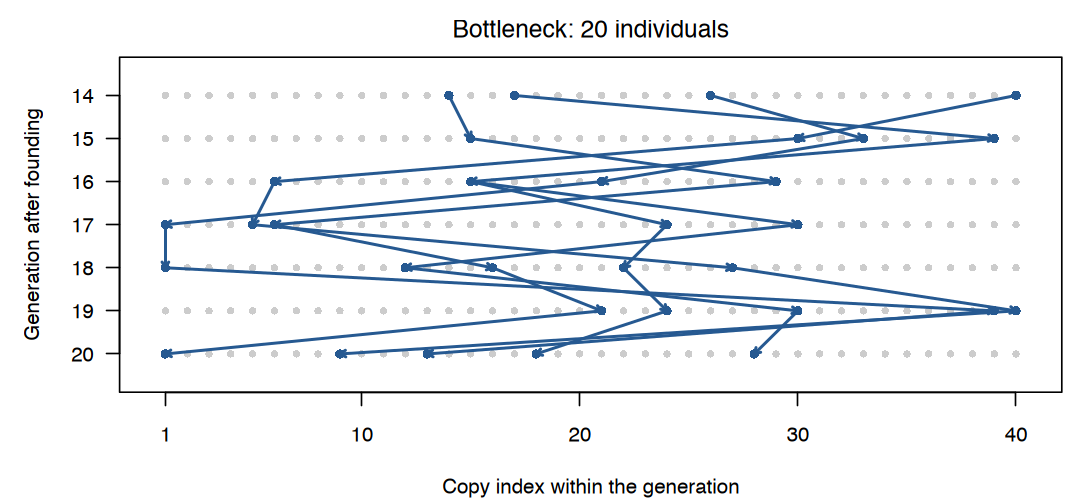

In [5]:
drawFigure("p5_recorded_paths", function() {
    par(mar = c(4.3, 4.6, 2.2, .7), bg = "white")
    end <- population_design$bottleneck_generations
    generations <- seq.int(end - 6L, end)
    pools <- lapply(generations, function(g) seq_len(40L))
    transmission <- simulation$records$copyParents$parents
    burnin <- population_design$burnin_generations
    copies <- as.vector(rbind(2L * simulation$truth$sample_indices - 1L,
                              2L * simulation$truth$sample_indices))[1:12]
    for (g in seq.int(60L, end + 1L)) copies <- transmission[[burnin + g]][copies, 1L]
    ancestors <- vector("list", length(generations))
    ancestors[[length(generations)]] <- unique(copies)
    for (i in seq.int(length(generations) - 1L, 1L))
        ancestors[[i]] <- unique(transmission[[burnin + generations[i+1L]]][ancestors[[i+1L]], 1L])
    maximum <- max(lengths(pools))
    plot(NA, xlim = c(.5, maximum + .5), ylim = c(end + .6, generations[1L] - .6),
         xaxt = "n", yaxt = "n", xlab = "Copy index within the generation",
         ylab = "Generation after founding", main = "Bottleneck: 20 individuals")
    axis(1, c(1, 10, 20, 30, 40))
    axis(2, generations, generations, las = 1)
    for (i in seq_along(pools))
        points(seq_along(pools[[i]]), rep(generations[i], length(pools[[i]])),
               pch = 16, cex = .65, col = "gray80")
    for (i in seq_len(length(generations) - 1L)) {
        child <- ancestors[[i + 1L]]
        parent <- transmission[[burnin + generations[i+1L]]][child, 1L]
        arrows(match(parent, pools[[i]]), rep(generations[i], length(child)),
               match(child, pools[[i + 1L]]), rep(generations[i + 1L], length(child)),
               length = .055, col = blue, lwd = 1.8)
    }
    for (i in seq_along(ancestors))
        points(match(ancestors[[i]], pools[[i]]), rep(generations[i], length(ancestors[[i]])),
               pch = 16, cex = .85, col = blue)
}, width = 6.8, height = 5.4)


## Read ages and branch lengths on the recorded tree

Collapse paths with a single child while keeping branching ancestors and
all twelve sampled-copy labels. Integer-time simultaneous mergers remain.
The simulation recorded the ancestral burn-in as well as the founder event
and expansion, so ancestors older than founding are part of the same record.

$T_{1,2}$ is the age of H1 and H2's common ancestor. $T_{\rm MRCA}$ is the
root age for all twelve copies. Here both are **461 generations**: H1 and H2
meet at the root. A branch spans its parent age minus its child age.
A node age and a waiting interval are different quantities.



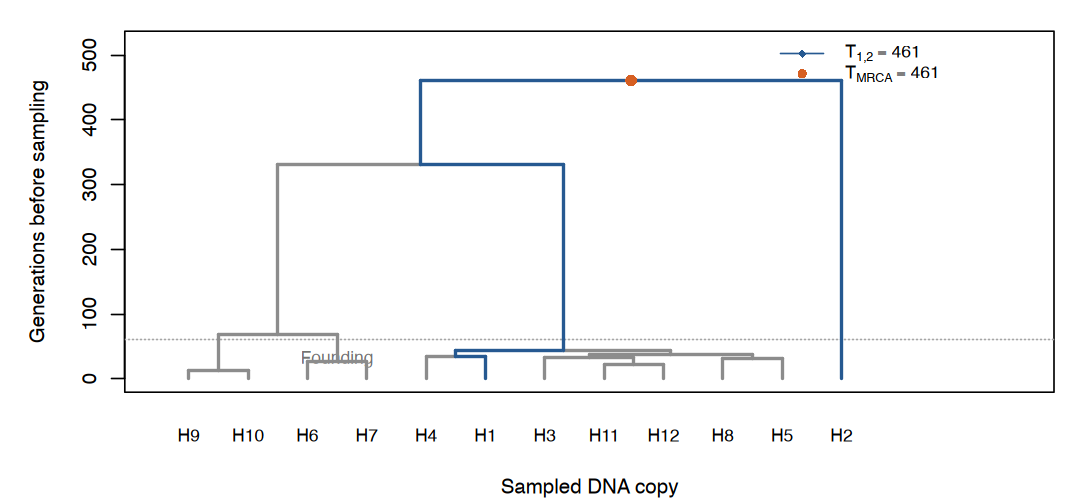

In [6]:
drawFigure("p5_recorded_tree", function() {
    par(mar = c(4.3, 4.8, 1.2, 1), bg = "white")
    drawRecordedTree(tree)
})
stopifnot(sum(tree_summary$branch_generations) == tree_summary$total_branch_length,
          sum(tree_summary$waiting_times) == tree_summary$TMRCA)


agg_record_18446262ce418 
                       2

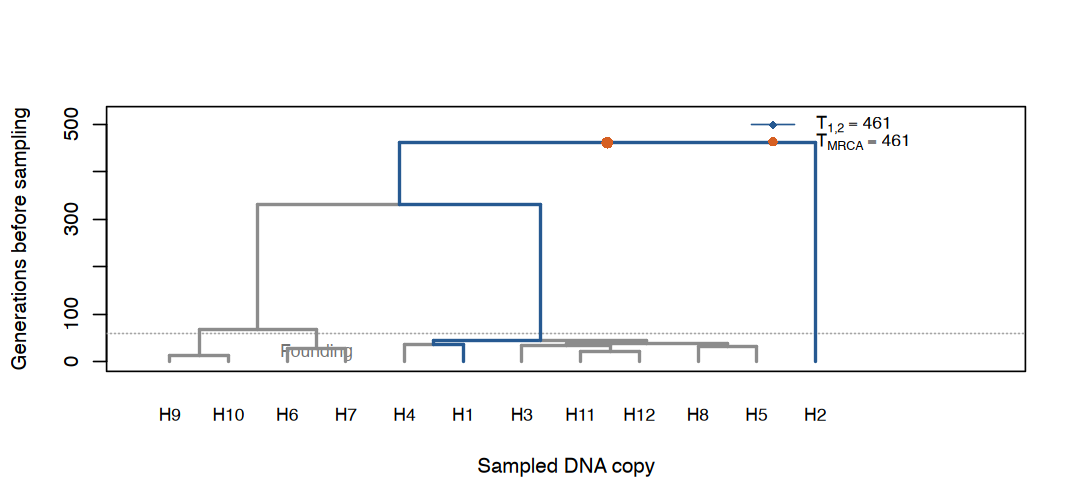

In [7]:
directory <- Sys.getenv("P8149_FIGURE_DIR")
if (nzchar(directory)) {
    pdf(file.path(directory,"coalescent_genealogy.pdf"),width=9,height=4.5,
        family="Helvetica",pointsize=13,useDingbats=FALSE,bg="white")
    for (cutoff in c(0,sort(unique(tree$nodes$time[tree$nodes$time>0])))) {
        par(mar=c(4.4,4.8,1.5,.8))
        drawRecordedTree(tree,cutoff=cutoff)
    }
    dev.off()
}
if ("IRkernel" %in% loadedNamespaces()) drawRecordedTree(tree)


## Founder identity and allele differences

As a mechanism check, isolate the same 20-individual, 20-generation bottleneck.
Set mutation to zero and follow founder labels and binary alleles through the
same parental draws. This control checks
$E(1-F_t)=E(H_t)/H_0=(1-1/(2N))^t$; it is not a new observed DNA dataset.


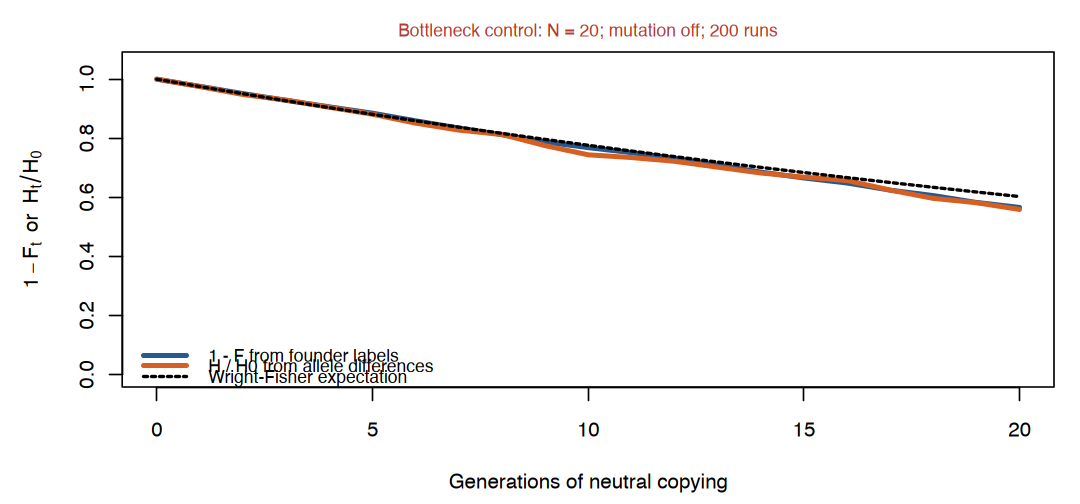

In [8]:
founder_check <- founderDiversityExample(N = population_design$founder_size,
    generations = population_design$bottleneck_generations)
drawFigure("founder_ibd_diversity_check", function() {
    x <- founder_check$summary
    par(mar = c(4.5, 4.7, 2, 1), bg = "white")
    plot(x$generation, x$nonIBD, type = "l", col = blue, lwd = 3,
         ylim = c(0, 1.05), xlab = "Generations of neutral copying",
         ylab = expression(1-F[t]~~"or"~~H[t]/H[0]))
    lines(x$generation, x$diversityRatio, col = orange, lwd = 3)
    lines(x$generation, x$expectation, lty = 2, lwd = 2)
    legend("bottomleft", c("1 - F from founder labels", "H / H0 from allele differences",
        "Wright-Fisher expectation"), col = c(blue, orange, "black"),
        lty = c(1, 1, 2), lwd = c(3, 3, 2), bty = "n", cex = .85)
    mtext("Bottleneck control: N = 20; mutation off; 200 runs", side = 3, line = .5,
          col = "#B33B32", cex = .85)
}, height = 3.8)


## Simulate the sample's ancestors

Two distinct lineages choose the same parent copy with probability $1/(2N)$ in each
discrete generation. For constant size, their waiting time has geometric survival
$\Pr(T_{\rm pair}>t)=(1-1/(2N))^t$. Its mean is $2N$ generations.

The large-population **Kingman coalescent** joins a uniformly chosen pair at
each ancestral event. With $k$ lineages and constant size, the waiting time is
exponential with rate $\binom{k}{2}/(2N_e)$. When size varies with ancestral age $t$,
use the current rate

$$
\lambda_k(t)=\frac{\binom{k}{2}}{2N_e(t)}.
$$

Update this rate when population size changes and continue to the sample MRCA. A branch of length $b$ receives a Poisson number
of mutations with mean $\mu Lb$; its descendants inherit those mutations.
The later comparison uses independent random genealogies from each model.


### A pair sampled before founding

For a constant-size reference, use the same ancestral $N_e=100$, mutation
rate $2.5\times10^{-5}$ and 10,000-base chromosome length. Turn recombination
off to isolate a single genealogy. The mean pairwise age is 200 generations.
The Poisson clock predicts 100 differences on average. This calculation is
conditional on the nonrecombining infinite-sites approximation.


        mean_wait        model_wait  mean_differences model_differences 
        199.14800         200.00000          99.53933         100.00000 


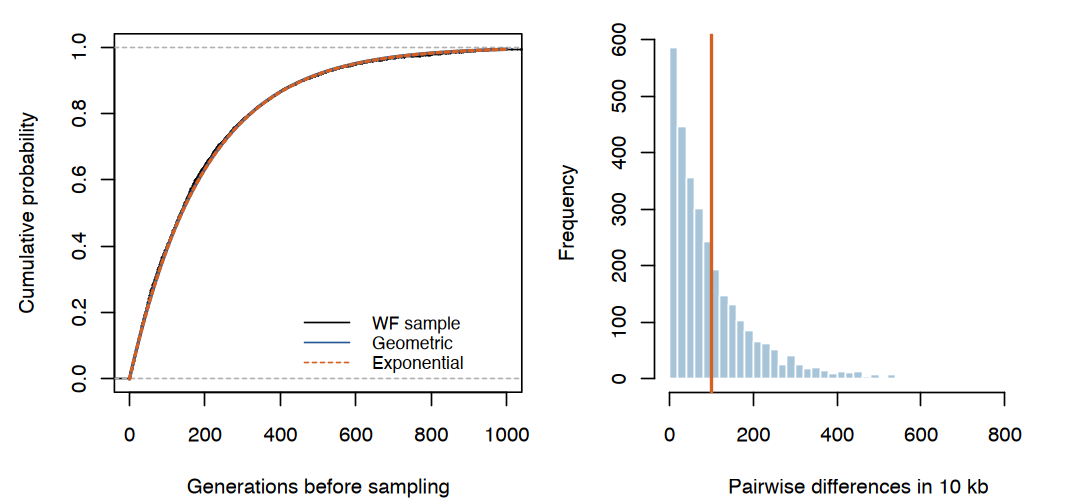

In [9]:
set.seed(9001)
Ne <- population_design$ancestral_size
mu <- population_design$mutation_rate
L <- population_design$sites_per_chromosome
T2 <- rgeom(3000, prob = 1 / (2 * Ne)) + 1
differences <- rpois(length(T2), lambda = 2 * mu * L * T2)
stopifnot(all(T2 >= 1), all(differences >= 0))
print(c(mean_wait = mean(T2), model_wait = 2 * Ne,
        mean_differences = mean(differences), model_differences = 4 * Ne * mu * L))
drawFigure("p5_pair_waiting", function() {
    par(mfrow = c(1, 2), mar = c(4.3, 4.4, 1.3, .7), bg = "white")
    plot(ecdf(T2), xlim = c(0, 1000), verticals = TRUE, do.points = FALSE,
         xlab = "Generations before sampling", ylab = "Cumulative probability", main = "")
    curve(1 - (1 - 1 / (2 * Ne))^floor(x), add = TRUE, col = blue, lwd = 2)
    curve(1 - exp(-x / (2 * Ne)), add = TRUE, col = orange, lty = 2, lwd = 2)
    legend("bottomright", c("WF sample", "Geometric", "Exponential"),
           col = c("black", blue, orange), lty = c(1, 1, 2), bty = "n", cex = .85,
           y.intersp = 1.8, inset = c(.02, .04))
    hist(differences, breaks = 35, col = "#A7C4D9", border = "white",
         xlab = "Pairwise differences in 10 kb", main = "")
    abline(v = 4 * Ne * mu * L, col = orange, lwd = 2)
})


## Compare discrete WF ancestry with the Kingman approximation

Draw 200 genealogies per model, with twelve sampled haplotypes and the same
founder, bottleneck and expansion history. The discrete Wright–Fisher calculation
follows sampled ancestors backward, one generation at a time. Kingman uses
continuous waiting times with the same generation-specific population sizes.

The second experiment multiplies all population sizes and durations by ten:
ancestral size 100 to 1,000, founders 20 to 200, final size 1,000 to 10,000,
bottleneck duration 20 to 200 generations and growth duration 40 to 400 generations.
The sample stays at twelve copies. Divide the mutation rate by ten to keep
mutation exposure comparable in the sequence comparison below.

This tests the Kingman approximation as the sample becomes a smaller fraction
of the population. The plot shows actual generations; compare the two models
within each panel. Each branch receives the same symmetric binary mutation model.


In [10]:
matched_main <- matchedHistoryDraws(replicates = 200L, baseSeed = 7814900L)


 scale       model pair_time     TMRCA       S pi_region multifurcation
     1 Discrete WF  128.3500  278.0400 228.320  70.03432          0.185
    10 Discrete WF 1448.4200 2739.5950 227.415  70.48591          0.025
     1     Kingman  148.5218  290.1132 231.140  73.49530          0.000
    10     Kingman 1323.1169 2656.7747 224.020  68.04977          0.000


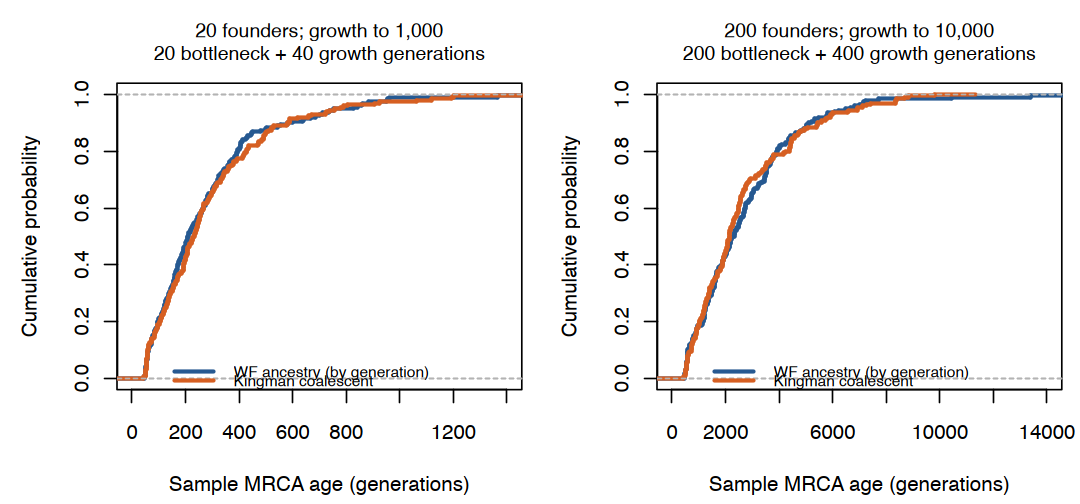

In [11]:
matched_scaled <- matchedHistoryDraws(replicates = 200L, scale = 10L, baseSeed = 8814900L)
matched <- rbind(matched_main$results, matched_scaled$results)
stopifnot(!anyDuplicated(c(matched$ancestry_seed, matched$mutation_seed)))
print(aggregate(cbind(pair_time, TMRCA, S, pi_region, multifurcation) ~ scale + model,
    matched, mean), row.names = FALSE)
drawFigure("p5_matched_genealogies", function() {
    par(mfrow = c(1, 2), mar = c(4.4, 4.5, 3.2, .7))
    for (scale in c(1, 10)) {
        z <- matched[matched$scale == scale, ]
        title <- if (scale == 1)
            "20 founders; growth to 1,000\n20 bottleneck + 40 growth generations" else
            "200 founders; growth to 10,000\n200 bottleneck + 400 growth generations"
        plot(ecdf(z$TMRCA[z$model == "Discrete WF"]),
            verticals = TRUE, do.points = FALSE, col = blue, lwd = 2.5,
            xlim = c(0, 1400 * scale), xlab = "Sample MRCA age (generations)",
            ylab = "Cumulative probability", main = title, cex.main = .95)
        lines(ecdf(z$TMRCA[z$model == "Kingman"]),
            verticals = TRUE, do.points = FALSE, col = orange, lwd = 2.5)
        legend("bottomright", c("WF ancestry (by generation)", "Kingman coalescent"),
            col = c(blue, orange), lty = 1, lwd = 2.5, bty = "n", cex = .75)
    }
}, height = 3.8)


### Simultaneous mergers

Discrete generations can merge more than two lineages at once. Kingman
joins one pair per event. Compare the frequency of multifurcating nodes in
the same repeated histories; the tenfold size-and-time scaling reduces them.
For $n$ distinct copies in one generation, the no-merger probability is
$\prod_{j=0}^{n-1}(1-j/(2N))$.


 scale       model multifurcation
     1 Discrete WF          0.185
    10 Discrete WF          0.025
     1     Kingman          0.000
    10     Kingman          0.000


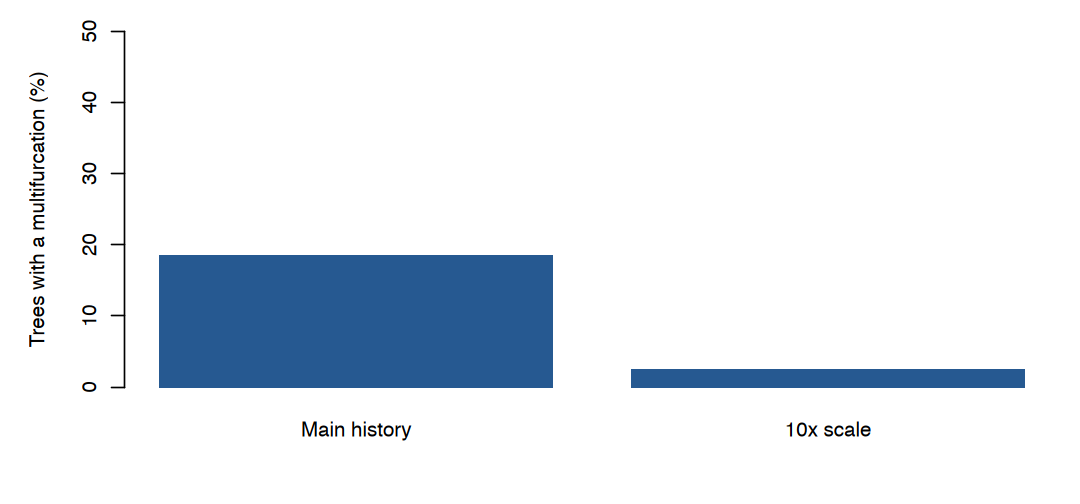

In [12]:
mergers <- aggregate(multifurcation ~ scale + model, matched, mean)
print(mergers, row.names = FALSE)
drawFigure("p5_recent_mergers", function() {
    par(mar = c(4.5, 4.8, 1.2, .8))
    z <- mergers[mergers$model == "Discrete WF", ]
    barplot(100 * z$multifurcation, names.arg = c("Main history", "10x scale"),
        col = blue, border = NA, ylab = "Trees with a multifurcation (%)", ylim = c(0, 50))
}, width = 5, height = 3.5)


## Sequence variation on these genealogies

Both models use symmetric recurrent binary mutations on integer sites.
The red curve is the infinite-sites coalescent expectation under the actual
size schedule, computed from the demographic SFS expectation. It is an
approximation to the finite-site mutations, not $	heta/i$ for a constant population.
A root state of zero specifies the mutation overlay; main-DNA analyses use
the original forward states, including mutations older than the sample MRCA.

Both ancestry comparisons use the same Poisson branch-mutation overlay.
It approximates the main forward simulator's per-generation parental mutation step.


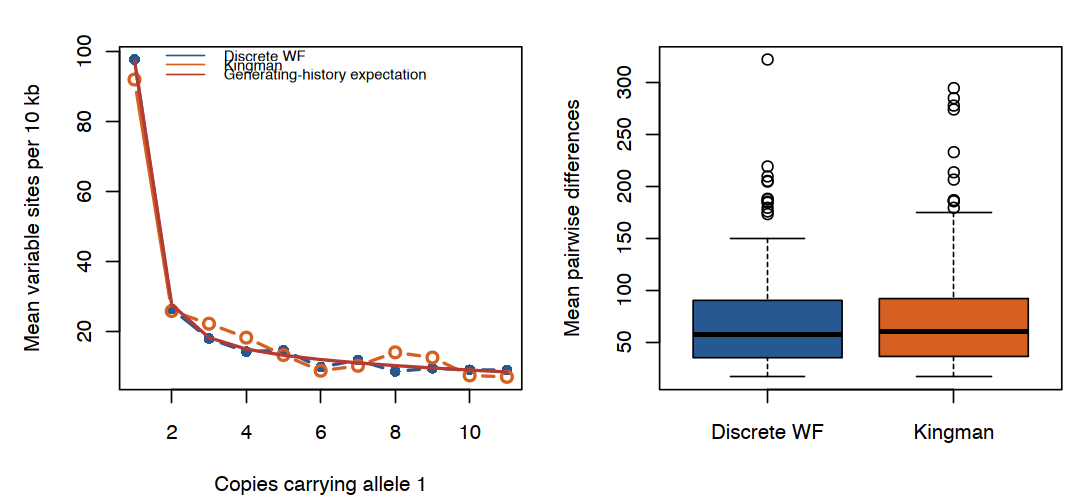

In [13]:
drawFigure("p5_matched_sequences", function() {
    par(mfrow = c(1, 2), mar = c(4.4, 4.6, 1.8, .7))
    means <- rbind(colMeans(matched_main$sfs[1:200, ]), colMeans(matched_main$sfs[201:400, ]))
    matplot(1:11, t(means), type = "b", pch = c(16, 1), lty = 1, lwd = 2,
        col = c(blue, orange), xlab = "Copies carrying allele 1", ylab = "Mean variable sites per 10 kb")
    lines(1:11, matched_main$expectation, col = "#B33B32", lwd = 2)
    legend("topright", c("Discrete WF", "Kingman", "Generating-history expectation"),
        col = c(blue, orange, "#B33B32"), lty = 1, bty = "n", cex = .72)
    boxplot(pi_region ~ model, data = matched[matched$scale == 1, ],
        col = c(blue, orange), ylab = "Mean pairwise differences", xlab = "")
})


## Constant-size summaries of a changing history

Apply $\widehat H/(4\mu)$ and $S/(4\mu L a_{n-1})$ to the same repeated
histories. Red lines show their infinite-sites expectations under the
generating history; neither must equal the ancestral size of 100.
For the fixed pair, also compare $\widehat T_{1,2}=M/(2\mu L)$ with its
recorded age. Recurrent mutation makes this Poisson clock approximate.


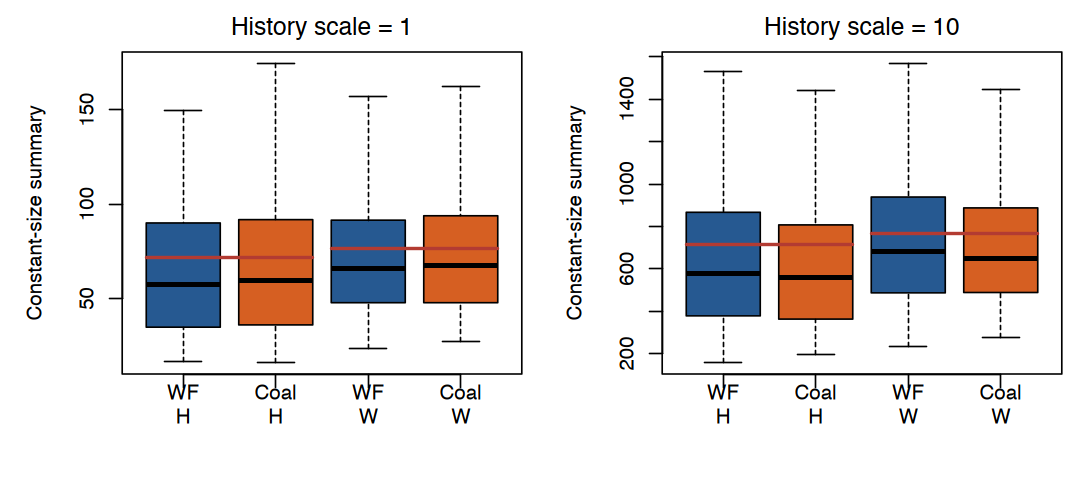

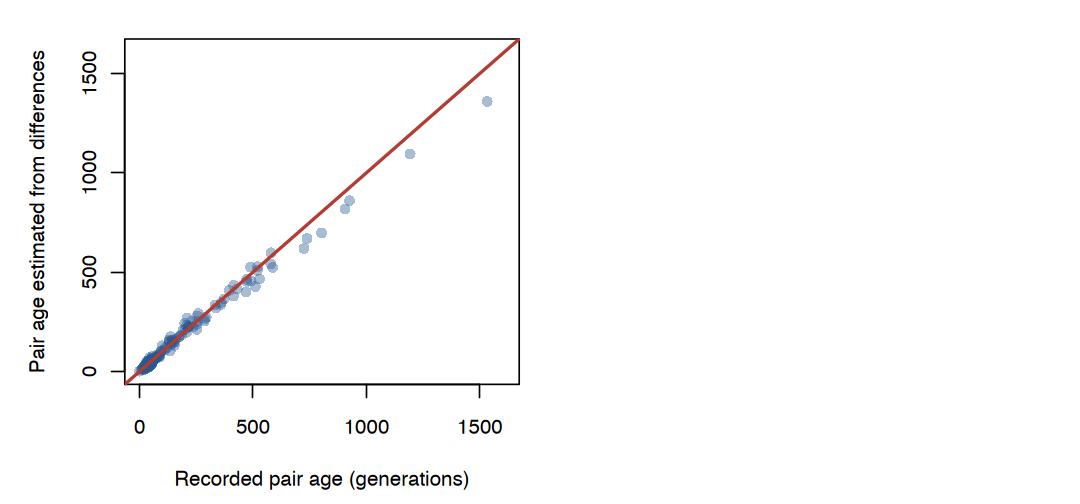

In [14]:
drawFigure("forward_coalescent_comparison", function() {
    par(mfrow = c(1, 2), mar = c(5, 4.7, 2, .7))
    for (scale in c(1, 10)) {
        bank <- if (scale == 1) matched_main else matched_scaled
        z <- bank$results; denom <- 4 * bank$mutationRate * bank$length
        wh <- 2 * (1:11) * (12 - (1:11)) / (12 * 11)
        boxplot(list(z$pi_region[z$model == "Discrete WF"] / denom,
            z$pi_region[z$model == "Kingman"] / denom,
            z$S[z$model == "Discrete WF"] / (sum(1/(1:11))*denom),
            z$S[z$model == "Kingman"] / (sum(1/(1:11))*denom)),
            names = c("WF\nH", "Coal\nH", "WF\nW", "Coal\nW"),
            col = c(blue, orange), outline = FALSE, ylab = "Constant-size summary",
            main = paste("History scale =", scale))
        target <- c(sum(bank$expectation*wh), sum(bank$expectation)/sum(1/(1:11))) / denom
        segments(c(.6,2.6), target, c(2.4,4.4), target, col = "#B33B32", lwd = 2)
    }
}, height = 3.6)
clock <- matched_main$results[matched_main$results$model == "Kingman", ]
clock$estimate <- clock$pair_differences / (2 * population_design$mutation_rate * 10000)
drawFigure("pairwise_time_recovery", function() {
    par(mar = c(4.6, 4.8, 1.5, .8))
    maximum <- max(clock$pair_time, clock$estimate)*1.05
    plot(clock$pair_time, clock$estimate, pch = 16, col = adjustcolor(blue,.4),
        xlim = c(0,maximum), ylim = c(0,maximum), xlab = "Recorded pair age (generations)",
        ylab = "Pair age estimated from differences")
    abline(0,1,col="#B33B32",lwd=2)
}, width = 5.2, height = 4.2)


The recorded tree describes the same sampled DNA at chromosome 1, site 5,000.
Its ancestral ages can be read directly from the forward transmission record.
The later repeated simulations check how well a coalescent approximation
reproduces discrete inheritance. Population size and sample fraction affect
that approximation, especially for recent mergers.

